In [1]:
import numpy as np
import matplotlib.pyplot as plt

pasta = '../dados/ps1_data/'
clima   = np.loadtxt(pasta + 'q6_weather.txt')
consumo = np.loadtxt(pasta + 'q6_demand.txt')

print('Clima:  ', clima.shape, '(linhas, colunas)')
print('Consumo:', consumo.shape, '(linhas, colunas)')

print('\nPrimeiras 3 linhas do clima:')
print(clima[:3])
print('\nPrimeiras 3 linhas do consumo:')
print(consumo[:3])

# --- Check-up do clima ---
nomes = ['tempo', 'temperatura', 'orvalho', 'umidade', 'pressão', 'vento', 'condição']
print('\nQuantos -9999 (dado faltando) em cada coluna do clima:')
for j, nome in enumerate(nomes):
    print(f'  {nome:12s}: {np.sum(clima[:, j] == -9999)}')

t = clima[:, 0]
print('\nHorários repetidos no clima:', len(t) - len(np.unique(t)))

Clima:   (41125, 7) (linhas, colunas)
Consumo: (35064, 2) (linhas, colunas)

Primeiras 3 linhas do clima:
[[1.19916666e+09 3.51000000e+01 2.41000000e+01 6.40000000e+01
  2.98000000e+01 4.60000000e+00 0.00000000e+00]
 [1.19917026e+09 3.70000000e+01 2.41000000e+01 5.90000000e+01
  2.97800000e+01 9.20000000e+00 0.00000000e+00]
 [1.19917386e+09 3.90000000e+01 3.20000000e+01 7.60000000e+01
  2.97800000e+01 1.15000000e+01 0.00000000e+00]]

Primeiras 3 linhas do consumo:
[[1.1991672e+09 1.4773450e+03]
 [1.1991708e+09 1.4144830e+03]
 [1.1991744e+09 1.3639220e+03]]

Quantos -9999 (dado faltando) em cada coluna do clima:
  tempo       : 0
  temperatura : 18
  orvalho     : 18
  umidade     : 18
  pressão     : 20
  vento       : 26
  condição    : 0

Horários repetidos no clima: 5


Linhas com algum -9999: 29
Depois de tirar os -9999: (41096, 7)
Depois de tirar os repetidos: (41091, 7)
Algum -9999 sobrando? False
Horários em ordem crescente? True


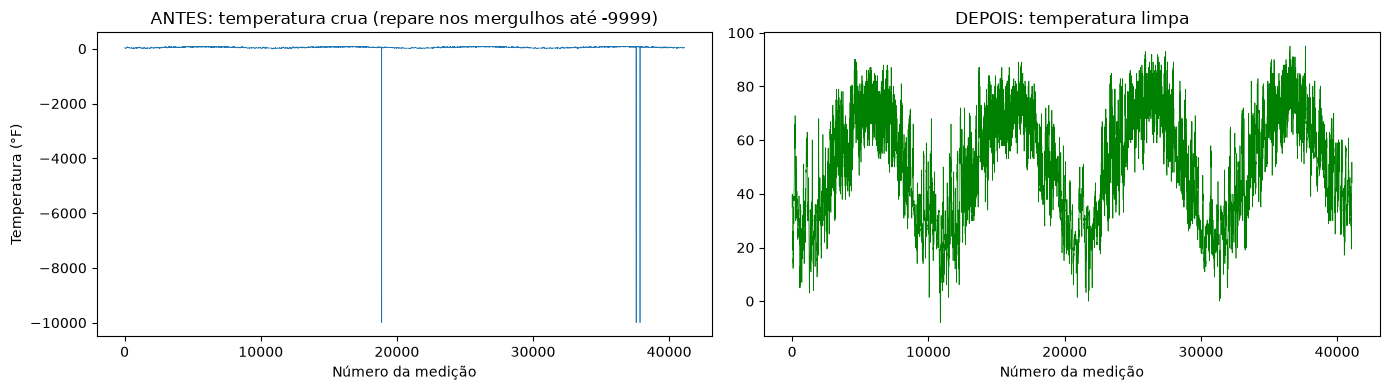

In [2]:
# --- 1. Jogar fora as linhas que têm -9999 em QUALQUER coluna ---
tem_defeito = np.any(clima == -9999, axis=1)       # para cada linha: "tem algum -9999?" (sim/não)
print('Linhas com algum -9999:', np.sum(tem_defeito))
clima_sem_9999 = clima[~tem_defeito]                # fica só com as linhas SEM defeito
print('Depois de tirar os -9999:', clima_sem_9999.shape)

# --- 2. Horários repetidos: ficar com a PRIMEIRA medição de cada horário ---
_, primeira_vez = np.unique(clima_sem_9999[:, 0], return_index=True)
clima_limpo = clima_sem_9999[primeira_vez]
print('Depois de tirar os repetidos:', clima_limpo.shape)

# --- 3. Conferências ---
print('Algum -9999 sobrando?', np.any(clima_limpo == -9999))
print('Horários em ordem crescente?', np.all(np.diff(clima_limpo[:, 0]) > 0))

# --- 4. Antes e depois, em gráfico ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(clima[:, 1], linewidth=0.5)
ax1.set_title('ANTES: temperatura crua (repare nos mergulhos até -9999)')
ax1.set_xlabel('Número da medição')
ax1.set_ylabel('Temperatura (°F)')
ax2.plot(clima_limpo[:, 1], linewidth=0.5, color='green')
ax2.set_title('DEPOIS: temperatura limpa')
ax2.set_xlabel('Número da medição')
plt.tight_layout()
plt.show()

Horas de consumo dentro do período do clima: 35039 de 35064

Primeiras 3 horas da tabela sincronizada:
     quando      | consumo (MW) | temp (°F) | condição
1199167200 |       1477.3 |     35.38 | 0
1199170800 |       1414.5 |     37.30 | 0
1199174400 |       1363.9 |     39.00 | 0


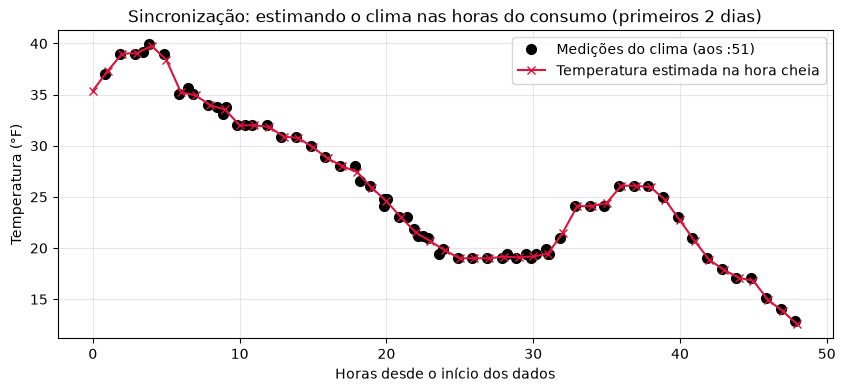

In [3]:
t_clima = clima_limpo[:, 0]                      # horários das medições do clima (já limpos e em ordem)

# --- Ficar só com as horas de consumo que estão DENTRO do período do clima ---
dentro = (consumo[:, 0] >= t_clima[0]) & (consumo[:, 0] <= t_clima[-1])
consumo_ok = consumo[dentro]
t_hora  = consumo_ok[:, 0]                       # as horas cheias
demanda = consumo_ok[:, 1]                       # o consumo de cada hora (MW)
print('Horas de consumo dentro do período do clima:', len(t_hora), 'de', len(consumo))

# --- Interpolar cada medida do clima para as horas cheias ---
# np.interp(onde quero saber, onde eu tenho medição, o valor medido)
temperatura = np.interp(t_hora, t_clima, clima_limpo[:, 1])
orvalho     = np.interp(t_hora, t_clima, clima_limpo[:, 2])
umidade     = np.interp(t_hora, t_clima, clima_limpo[:, 3])
pressao     = np.interp(t_hora, t_clima, clima_limpo[:, 4])
vento       = np.interp(t_hora, t_clima, clima_limpo[:, 5])

# --- Condição: pegar a medição MAIS PRÓXIMA (não dá para fazer "média" de etiquetas) ---
posicao = np.round(np.interp(t_hora, t_clima, np.arange(len(t_clima)))).astype(int)
condicao = clima_limpo[posicao, 6]

# --- Conferir as primeiras horas ---
print('\nPrimeiras 3 horas da tabela sincronizada:')
print('     quando      | consumo (MW) | temp (°F) | condição')
for i in range(3):
    print(f'{t_hora[i]:.0f} | {demanda[i]:12.1f} | {temperatura[i]:9.2f} | {condicao[i]:.0f}')

# --- Ver de perto: 2 dias ---
ini = t_hora[0]
fim = ini + 2 * 86400                            # 2 dias depois (86.400 s = 1 dia)
m_c = (t_clima >= ini) & (t_clima <= fim)
m_h = (t_hora  >= ini) & (t_hora  <= fim)
plt.figure(figsize=(10, 4))
plt.plot((t_clima[m_c] - ini) / 3600, clima_limpo[m_c, 1], 'o', color='black', markersize=7,
         label='Medições do clima (aos :51)')
plt.plot((t_hora[m_h] - ini) / 3600, temperatura[m_h], 'x-', color='crimson', markersize=6,
         label='Temperatura estimada na hora cheia')
plt.xlabel('Horas desde o início dos dados')
plt.ylabel('Temperatura (°F)')
plt.title('Sincronização: estimando o clima nas horas do consumo (primeiros 2 dias)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Quantos dias: 1460
Dias na questão 5: 1460
Diferença média na temperatura: 0.072 °F
Diferença média no consumo:    0.0 GW


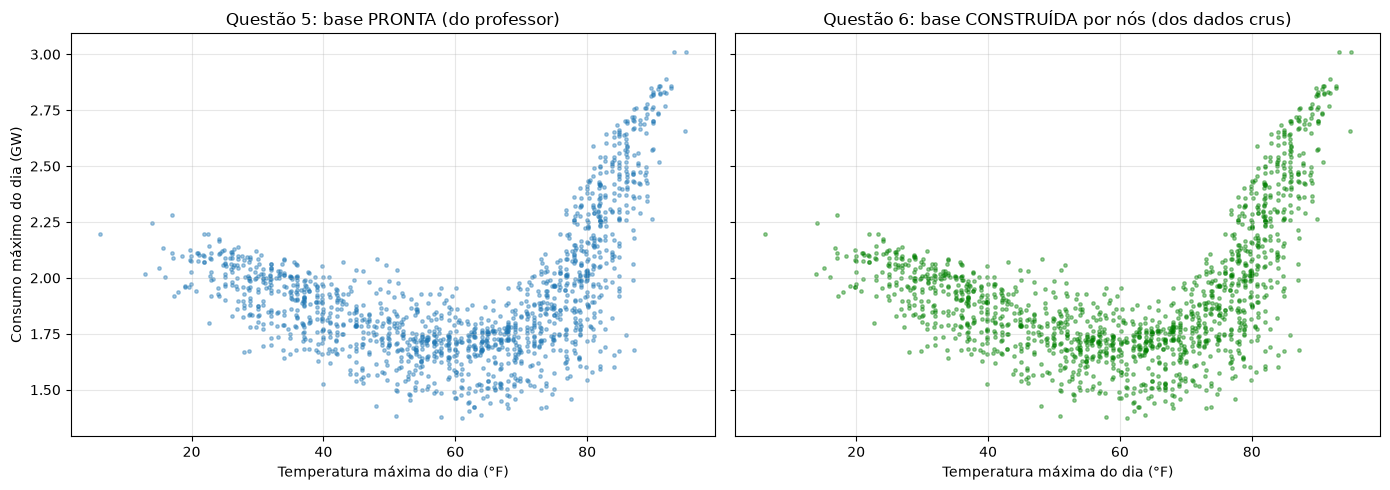

In [4]:
# --- 1. Passar do horário de Londres para o de Pittsburgh (5 horas a menos) ---
t_local = t_hora - 5 * 3600

# --- 2. Número do dia de cada hora ---
dia = np.floor(t_local / 86400).astype(int)       # floor = "jogar fora a parte depois da vírgula"
lista_dias = np.unique(dia)                        # cada dia, uma vez só
print('Quantos dias:', len(lista_dias))

# --- 3. Para cada dia, pegar o maior consumo e a maior temperatura ---
max_demanda = []
max_temp = []
for d in lista_dias:
    deste_dia = (dia == d)                         # "quais horas são deste dia?"
    max_demanda.append(demanda[deste_dia].max())
    max_temp.append(temperatura[deste_dia].max())

max_demanda = np.array(max_demanda) / 1000         # MW -> GW (igual à questão 5)
max_temp = np.array(max_temp)

# --- 4. Comparar com a base pronta da questão 5 ---
x5 = np.loadtxt(pasta + 'q5_max_temp.txt')
y5 = np.loadtxt(pasta + 'q5_max_demand.txt')
print('Dias na questão 5:', len(x5))
print('Diferença média na temperatura:', round(np.mean(np.abs(max_temp - x5)), 3), '°F')
print('Diferença média no consumo:   ', round(np.mean(np.abs(max_demanda - y5)), 6), 'GW')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
ax1.scatter(x5, y5, s=6, alpha=0.4)
ax1.set_title('Questão 5: base PRONTA (do professor)')
ax2.scatter(max_temp, max_demanda, s=6, alpha=0.4, color='green')
ax2.set_title('Questão 6: base CONSTRUÍDA por nós (dos dados crus)')
for ax in (ax1, ax2):
    ax.set_xlabel('Temperatura máxima do dia (°F)')
    ax.grid(True, alpha=0.3)
ax1.set_ylabel('Consumo máximo do dia (GW)')
plt.tight_layout()
plt.savefig('../figuras/item6c_comparacao.png', dpi=150, bbox_inches='tight')
plt.show()

Maior pressão no arquivo "limpo": 299.67
Medições de pressão absurdas: 1
Tabela diária: (1460, 8) (dias, informações)

 T.máx | T.mín | Orvalho | Umid. | Pressão | Vento | Cond. | Dia | Consumo (GW)
  39.8 |  21.5 |    23.0 |  70.0 |   29.87 |  16.0 |     2 | Ter | 1.890
  26.1 |  14.9 |     9.4 |  63.6 |   30.28 |  14.5 |     2 | Qua | 2.109
  19.8 |  12.5 |     8.6 |  72.9 |   30.70 |   7.7 |     2 | Qui | 2.125
  35.1 |  12.9 |     8.3 |  53.7 |   30.54 |   7.3 |     3 | Sex | 2.005
  41.0 |  28.9 |    22.4 |  62.4 |   30.27 |   7.5 |     0 | Sáb | 1.869


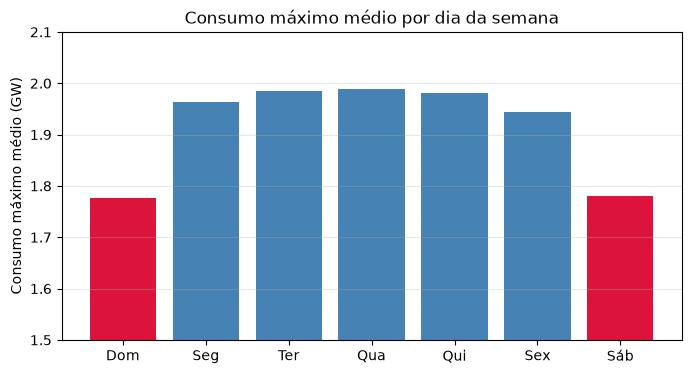

In [5]:
# --- 1. O defeito escondido na pressão ---
print('Maior pressão no arquivo "limpo":', clima_limpo[:, 4].max())
pressao_ok = (clima_limpo[:, 4] > 28) & (clima_limpo[:, 4] < 32)      # faixa razoável
print('Medições de pressão absurdas:', np.sum(~pressao_ok))
pressao = np.interp(t_hora, t_clima[pressao_ok], clima_limpo[pressao_ok, 4])   # refaz só a pressão

# --- 2. Uma linha por dia, com todas as informações ---
rng = np.random.default_rng(0)          # para sortear empates sempre do mesmo jeito
linhas = []
consumo_dia = []
for d in lista_dias:
    h = (dia == d)                                          # as horas deste dia
    codigos, quantas = np.unique(condicao[h], return_counts=True)
    empatados = codigos[quantas == quantas.max()]           # condições que mais apareceram
    mais_comum = rng.choice(empatados)                      # se houver empate, sorteia (o PDF pede)
    dia_semana = (d + 4) % 7                                # 0 = domingo ... 6 = sábado
    linhas.append([temperatura[h].max(), temperatura[h].min(),
                   orvalho[h].mean(), umidade[h].mean(), pressao[h].mean(), vento[h].mean(),
                   mais_comum, dia_semana])
    consumo_dia.append(demanda[h].max() / 1000)              # consumo máximo do dia, em GW

tabela = np.array(linhas)
Y = np.array(consumo_dia)
print('Tabela diária:', tabela.shape, '(dias, informações)')

# --- 3. Ver os primeiros dias ---
nomes_dia = ['Dom', 'Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb']
print('\n T.máx | T.mín | Orvalho | Umid. | Pressão | Vento | Cond. | Dia | Consumo (GW)')
for i in range(5):
    r = tabela[i]
    print(f'{r[0]:6.1f} | {r[1]:5.1f} | {r[2]:7.1f} | {r[3]:5.1f} | {r[4]:7.2f} | {r[5]:5.1f} '
          f'| {r[6]:5.0f} | {nomes_dia[int(r[7])]} | {Y[i]:.3f}')

# --- 4. Consumo médio por dia da semana ---
medias = [Y[tabela[:, 7] == k].mean() for k in range(7)]
plt.figure(figsize=(8, 4))
plt.bar(nomes_dia, medias, color=['crimson', 'steelblue', 'steelblue', 'steelblue',
                                  'steelblue', 'steelblue', 'crimson'])
plt.ylim(1.5, 2.1)
plt.ylabel('Consumo máximo médio (GW)')
plt.title('Consumo máximo médio por dia da semana')
plt.grid(True, alpha=0.3, axis='y')
plt.savefig('../figuras/item6d_dia_semana.png', dpi=150, bbox_inches='tight')
plt.show()

Modelo                              | colunas | erro caderno | erro prova | RMSE prova (GW)
--------------------------------------------------------------------------------------------
Q5: só T.máx (grau 3)               |       4 |       0.0252 |     0.0251 | 0.158
+ T.mín                             |       7 |       0.0203 |     0.0204 | 0.143
+ orvalho, umidade, pressão, vento  |      11 |       0.0196 |     0.0200 | 0.141
+ condição do tempo                 |      23 |       0.0189 |     0.0198 | 0.141
+ dia da semana (nossa ideia)       |      29 |       0.0100 |     0.0106 | 0.103


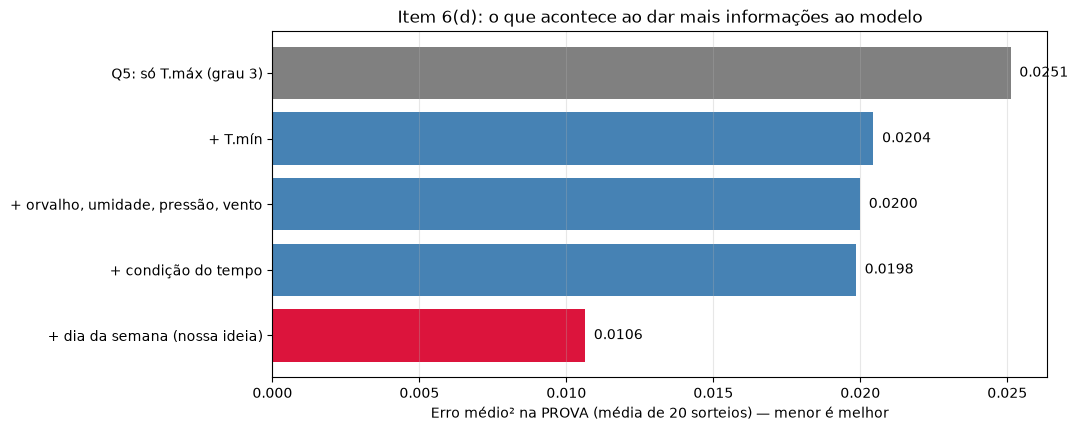

In [6]:
# --- 1. Mesma régua: média 0 e variação típica 1 em cada coluna ---
Z = (tabela - tabela.mean(axis=0)) / tabela.std(axis=0)

# --- 2. Receitas para montar as colunas ---
def potencias(coluna):                     # z, z², z³ (o polinômio de grau 3)
    return np.column_stack([coluna, coluna**2, coluna**3])

def sim_nao(coluna):                       # uma coluna "sim/não" para cada categoria (menos a primeira)
    categorias = np.unique(coluna)
    return np.column_stack([coluna == c for c in categorias[1:]]).astype(float)

um      = np.ones((len(Y), 1))             # a velha coluna de 1
p_tmax  = potencias(Z[:, 0])               # temperatura máxima (grau 3)
p_tmin  = potencias(Z[:, 1])               # temperatura mínima (grau 3)
medias  = Z[:, 2:6]                        # orvalho, umidade, pressão, vento
cond    = sim_nao(tabela[:, 6])            # condição do tempo -> perguntas sim/não
semana  = sim_nao(tabela[:, 7])            # dia da semana     -> perguntas sim/não

# --- 3. Os modelos, acrescentando uma informação por vez ---
modelos = [
    ('Q5: só T.máx (grau 3)',              np.column_stack([p_tmax, um])),
    ('+ T.mín',                            np.column_stack([p_tmax, p_tmin, um])),
    ('+ orvalho, umidade, pressão, vento', np.column_stack([p_tmax, p_tmin, medias, um])),
    ('+ condição do tempo',                np.column_stack([p_tmax, p_tmin, medias, cond, um])),
    ('+ dia da semana (nossa ideia)',      np.column_stack([p_tmax, p_tmin, medias, cond, semana, um])),
]

# --- 4. Avaliar cada modelo em 20 sorteios de caderno/prova ---
print('Modelo                              | colunas | erro caderno | erro prova | RMSE prova (GW)')
print('-' * 92)
nomes_modelos, erros_prova = [], []
for nome, Phi in modelos:
    e_cad, e_pro = [], []
    for sorteio in range(20):
        ordem = np.random.default_rng(sorteio).permutation(len(Y))
        cad, pro = ordem[:1095], ordem[1095:]                     # 75% caderno, 25% prova
        theta = np.linalg.lstsq(Phi[cad], Y[cad], rcond=None)[0]  # aprende SÓ com o caderno
        e_cad.append(np.mean((Phi[cad] @ theta - Y[cad])**2))
        e_pro.append(np.mean((Phi[pro] @ theta - Y[pro])**2))    # avalia na prova
    nomes_modelos.append(nome)
    erros_prova.append(np.mean(e_pro))
    print(f'{nome:35s} | {Phi.shape[1]:7d} | {np.mean(e_cad):12.4f} | {np.mean(e_pro):10.4f} '
          f'| {np.sqrt(np.mean(e_pro)):.3f}')

# --- 5. Gráfico ---
plt.figure(figsize=(10, 4.5))
cores = ['gray', 'steelblue', 'steelblue', 'steelblue', 'crimson']
plt.barh(nomes_modelos[::-1], erros_prova[::-1], color=cores[::-1])
for i, e in enumerate(erros_prova[::-1]):
    plt.text(e + 0.0003, i, f'{e:.4f}', va='center')
plt.xlabel('Erro médio² na PROVA (média de 20 sorteios) — menor é melhor')
plt.title('Item 6(d): o que acontece ao dar mais informações ao modelo')
plt.grid(True, alpha=0.3, axis='x')
plt.savefig('../figuras/item6d_comparacao_modelos.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
import time

# --- As três "tabelas Φ", com todas as informações + dia da semana ---
X_reta = np.column_stack([Z[:, 0:6], cond, semana, um])                     # tudo como reta
X_poli = np.column_stack([potencias(Z[:, 0]), potencias(Z[:, 1]),
                          Z[:, 2:6], cond, semana, um])                      # temperaturas com grau 3
X_kern = np.column_stack([Z[:, 0:6], cond, semana])                         # para o kernel

# --- Erro na prova para a fórmula pronta (reta e polinômio) ---
def erro_formula(X):
    erros = []
    for sorteio in range(20):
        ordem = np.random.default_rng(sorteio).permutation(len(Y))
        cad, pro = ordem[:1095], ordem[1095:]
        theta = np.linalg.lstsq(X[cad], Y[cad], rcond=None)[0]
        erros.append(np.mean((X[pro] @ theta - Y[pro])**2))
    return np.mean(erros)

# --- Sininho em várias dimensões: dois dias são parecidos se parecem em TUDO ---
def semelhanca(A, B, sigma):
    dist2 = ((A[:, None, :] - B[None, :, :])**2).sum(axis=2)   # soma das diferenças² de todas as colunas
    return np.exp(-dist2 / (2 * sigma**2))

# --- Erro na prova para o kernel ---
def erro_kernel(X, sigma, lam):
    erros = []
    for sorteio in range(20):
        ordem = np.random.default_rng(sorteio).permutation(len(Y))
        cad, pro = ordem[:1095], ordem[1095:]
        media = Y[cad].mean()                                     # o kernel prevê a diferença em relação à média
        K = semelhanca(X[cad], X[cad], sigma)
        alpha = np.linalg.solve(K + lam * np.eye(len(cad)), Y[cad] - media)
        previsto = semelhanca(X[pro], X[cad], sigma) @ alpha + media
        erros.append(np.mean((previsto - Y[pro])**2))
    return np.mean(erros)

# --- Rodar tudo ---
inicio = time.time()
resultados = [('Só retas (linear)', erro_formula(X_reta)),
              ('Polinômio grau 3 nas temperaturas', erro_formula(X_poli))]
for sigma, lam in [(2, 0.1), (3, 0.1), (5, 0.01)]:
    resultados.append((f'Kernel gaussiano (σ={sigma}, λ={lam})', erro_kernel(X_kern, sigma, lam)))
print(f'(levou {time.time() - inicio:.0f} segundos)\n')

print('Modelo (todas as informações + dia da semana) | erro prova | RMSE (GW)')
print('-' * 72)
for nome, e in resultados:
    print(f'{nome:46s} | {e:10.4f} | {np.sqrt(e):.3f}')

(levou 38 segundos)

Modelo (todas as informações + dia da semana) | erro prova | RMSE (GW)
------------------------------------------------------------------------
Só retas (linear)                              |     0.0536 | 0.231
Polinômio grau 3 nas temperaturas              |     0.0106 | 0.103
Kernel gaussiano (σ=2, λ=0.1)                  |     0.0085 | 0.092
Kernel gaussiano (σ=3, λ=0.1)                  |     0.0082 | 0.091
Kernel gaussiano (σ=5, λ=0.01)                 |     0.0084 | 0.092
